# Kuramoto–Sivashinsky (cellular regime)

$$
f_t = -\tfrac{1}{2}\,\|\nabla f\|^2 - \Delta f - \Delta^2 f
$$

## 1. Setup

In [1]:
import numpy as np

import nb_helpers as nb
from equivariant_pde_find.simulations import kuramoto_sivashinsky

EQ = "ks_cell"
NOISE = 0.02

# ── Best configurations from the hyperparameter sweep ───────────────
#
#   "eq"  = best of  multigraph / mod_multigraph
#   "neq" = best of  polyjet
#
# ────────────────────────────────────────────────────────────────────
BEST = {
    (0.00, "eq"): dict(
        library="multigraph", method="weak_direct", algorithm="stridge",
        backend="polynomial", m=12, lam=1e-6, d_tol=10.0,
    ),
    (0.00, "neq"): dict(
        library="polyjet", method="weak_direct", algorithm="rfe",
        backend="polynomial", m=12, lam=0.0,
    ),
    (0.02, "eq"): dict(
        library="multigraph", method="weak_direct", algorithm="stridge",
        backend="polynomial", m=12, lam=0.01, d_tol=10.0,
    ),
    (0.02, "neq"): dict(
        library="polyjet", method="weak_ibp", algorithm="mstls",
        backend="polynomial", m=12, alpha=0.75,
    ),
}

## 2. Generate the data

In [2]:
SIM = dict(N=64, L=4 * np.pi, T_end=50.0, dt=0.1,
           save_every=5, seed=42)

clean, times = kuramoto_sivashinsky(**SIM, obs_noise=0.0)
noisy, _ = kuramoto_sivashinsky(**SIM, obs_noise=NOISE)

print(f'{len(clean)} snapshots over t ∈ [{times[0]:.2f}, {times[-1]:.2f}]'
      f' on a {clean.shape[1]}×{clean.shape[2]} grid')
print(f'f ∈ [{clean.min():.3f}, {clean.max():.3f}]')
nb.check_matches_dataset(clean, EQ, 'clean')
nb.check_matches_dataset(noisy, EQ, 'noise2pct')

101 snapshots over t ∈ [0.10, 50.10] on a 64×64 grid
f ∈ [-37.316, 1.731]
  vs data/ks_cell_clean.npz: max|Δ| = 0.00e+00  → identical
  vs data/ks_cell_noise2pct.npz: max|Δ| = 0.00e+00  → identical


0.0

In [3]:
sigma = NOISE * clean.std()
fluct = clean - clean.mean(axis=(1, 2), keepdims=True)
print(f'global std           {clean.std():8.3f}   → noise σ = {sigma:.4f}')
print(f'fluctuation std      {fluct.std():8.3f}   → σ is {100 * sigma / fluct.std():.1f}% of the pattern')
print(f'late-time fluct std  {fluct[-1].std():8.3f}   → σ is {100 * sigma / fluct[-1].std():.1f}% of the pattern')

global std              9.939   → noise σ = 0.1988
fluctuation std         1.756   → σ is 11.3% of the pattern
late-time fluct std     2.679   → σ is 7.4% of the pattern


## 3. The motion

written: results/figures/ks_cell_motion.pdf
written: results/figures/ks_cell_motion.png


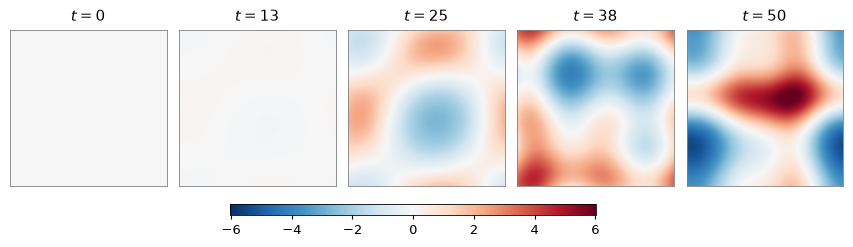

In [4]:
fig, paths = nb.plot_motion(
    clean, times, SIM['L'], n_frames=5,
    cmap='RdBu_r', symmetric=True, detrend=True,
    time_fmt='.0f',
    save_as=f'{EQ}_motion',
)
for p in paths:
    print('written:', p.split('/code/')[-1])

## 4. Design matrices

In [5]:
Lx = Ly = SIM['L']

data = {
    0.00: nb.regression_data(clean, times, EQ),
    NOISE: nb.regression_data(noisy, times, EQ),
}
print(f'{len(data[0.00][0])} interior snapshots')

ev = nb.JetEvaluator(clean, times, Lx, Ly, EQ)
ev.summary()

designs, fits = {}, {}
for key, cfg in BEST.items():
    f_snaps, ft_snaps, idx_sets, _ = data[key[0]]
    Theta, Ft, desc = nb.build_design(
        f_snaps, ft_snaps, idx_sets, Lx, Ly, cfg)
    designs[key] = (Theta, Ft, desc)
    fits[key] = nb.run_fit(Theta, Ft, cfg)
    print(f'{key[0] * 100:>3.0f}%  {key[1]:<4} {cfg["library"]:<15} '
          f'Theta {str(Theta.shape):<13} cond {np.linalg.cond(Theta):.2e}')

69 interior snapshots


Evaluation space: 119 jet monomials, 282,624 rows, 7 true active terms


  0%  eq   multigraph      Theta (6900, 20)    cond 1.25e+05


  0%  neq  polyjet         Theta (6900, 105)   cond 1.12e+06


  2%  eq   multigraph      Theta (6900, 20)    cond 6.89e+04


  2%  neq  polyjet         Theta (6900, 105)   cond 3.28e+05


## 5. Recovery with clean data

In [6]:
print('Ground truth:  f_t = −0.5·‖∇f‖² − Δf − Δ²f')
print()
for group in ('eq', 'neq'):
    key = (0.00, group)
    nb.show_recovery(fits[key], designs[key][2], BEST[key], ev)
    print()

Ground truth:  f_t = −0.5·‖∇f‖² − Δf − Δ²f

── Multigraph ──
   Multigraph · weak (direct) · STRidge · polynomial derivatives · m=12, p=6 · λ=1e-06, d_tol=10
   f_t = (-0.99720)Δf + (-0.49870)‖∇f‖² + (-0.99669)Δ²f
   3 active terms · fp=0 fn=0 · EXACT RECOVERY
   E_coeff = 0.002666   max|Δc| = 0.00662

── PolyJet ──
   PolyJet · weak (direct) · RFE · polynomial derivatives · m=12, p=6 · λ=0
   f_t = (-0.99637)f_xx + (-0.99861)f_yy + (-0.49870)f_x² + (-0.49870)f_y² + (-0.99522)f_xxxx + (-1.99019)f_xxyy + (-0.99962)f_yyyy
   7 active terms · fp=0 fn=0 · EXACT RECOVERY
   E_coeff = 0.003036   max|Δc| = 0.00981



In [7]:
for group in ('eq', 'neq'):
    key = (0.00, group)
    print(nb.LIBRARY_LABEL[BEST[key]['library']] + ':')
    nb.coefficient_table(
        fits[key], designs[key][2], BEST[key], ev)
    print()

Multigraph:
term       recovered        true       error
────────────────────────────────────────────
f_xxyy      -1.99338    -2.00000    6.62e-03
f_xx        -0.99720    -1.00000    2.80e-03
f_yy        -0.99720    -1.00000    2.80e-03
f_xxxx      -0.99669    -1.00000    3.31e-03
f_yyyy      -0.99669    -1.00000    3.31e-03
f_x²        -0.49870    -0.50000    1.30e-03
f_y²        -0.49870    -0.50000    1.30e-03

PolyJet:
term       recovered        true       error
────────────────────────────────────────────
f_xxyy      -1.99019    -2.00000    9.81e-03
f_xx        -0.99637    -1.00000    3.63e-03
f_yy        -0.99861    -1.00000    1.39e-03
f_xxxx      -0.99522    -1.00000    4.78e-03
f_yyyy      -0.99962    -1.00000    3.77e-04
f_x²        -0.49870    -0.50000    1.30e-03
f_y²        -0.49870    -0.50000    1.30e-03



## 6. Recovery at 2 % noise

In [8]:
print('Ground truth:  f_t = −0.5·‖∇f‖² − Δf − Δ²f')
print()
for group in ('eq', 'neq'):
    key = (NOISE, group)
    nb.show_recovery(fits[key], designs[key][2], BEST[key], ev)
    print()

Ground truth:  f_t = −0.5·‖∇f‖² − Δf − Δ²f

── Multigraph ──
   Multigraph · weak (direct) · STRidge · polynomial derivatives · m=12, p=6 · λ=0.01, d_tol=10
   f_t = (-0.55605)Δf + (-0.40074)‖∇f‖² + (-0.50084)Δ²f
   3 active terms · fp=0 fn=0 · EXACT RECOVERY
   E_coeff = 0.2711   max|Δc| = 0.998

── PolyJet ──
   PolyJet · weak (IBP) · MSTLS · polynomial derivatives · m=12, p=6 · α=0.75
   f_t = (+0.06137)1 + (-0.83271)f_xx + (-0.58035)f_yy + (-0.43145)f_x² + (-0.36185)f_y² + (-0.68453)f_xxxx + (+0.52522)f_xxyy + (-0.52863)f_yyyy + (-0.39385)f_xy² + (-0.26102)f_x·f_xyy + (+0.10515)f_x²·f_xx
   11 active terms · fp=4 fn=0 · not exact
   E_coeff = 0.3327   max|Δc| = 2.53



In [9]:
for group in ('eq', 'neq'):
    key = (NOISE, group)
    print(nb.LIBRARY_LABEL[BEST[key]['library']] + ':')
    nb.coefficient_table(
        fits[key], designs[key][2], BEST[key], ev)
    print()

Multigraph:
term       recovered        true       error
────────────────────────────────────────────
f_xxyy      -1.00168    -2.00000    9.98e-01
f_xx        -0.55605    -1.00000    4.44e-01
f_yy        -0.55605    -1.00000    4.44e-01
f_xxxx      -0.50084    -1.00000    4.99e-01
f_yyyy      -0.50084    -1.00000    4.99e-01
f_x²        -0.40074    -0.50000    9.93e-02
f_y²        -0.40074    -0.50000    9.93e-02

PolyJet:
term          recovered        true       error
───────────────────────────────────────────────
f_xxyy          0.52522    -2.00000    2.53e+00
f_xx           -0.83271    -1.00000    1.67e-01
f_yy           -0.58035    -1.00000    4.20e-01
f_xxxx         -0.68453    -1.00000    3.15e-01
f_yyyy         -0.52863    -1.00000    4.71e-01
f_x²           -0.43145    -0.50000    6.86e-02
f_y²           -0.36185    -0.50000    1.38e-01
1               0.06137     0.00000    6.14e-02  ← false positive
f_xy²          -0.39385     0.00000   -3.94e-01  ← false positive
f_x·f_xyy